# CNN para clasificación de **Residuos** (3 clases)

**Propósito**: entrenar un modelo de visión (Transfer Learning con EfficientNet-B0) que clasifica residuos según el código de colores de Colombia (Resolución 2184 de 2019):
- **Orgánico** (`organic`) → caneca verde
- **Reciclable** (`recyclable`) → caneca blanca
- **No reciclable** (`Norecyclable`) → caneca negra (pilas y electrónicos → punto posconsumo)

Basado en el notebook `CNN_Animals.ipynb`. Diferencias principales:
- Carga de datos con `torchvision` (`ImageFolder` + `DataLoader`) para entrenar completo en la **GPU**.
- *Mixed precision* (AMP) para acelerar el entrenamiento.
- Split estratificado **train / val / test (70/15/15)** por clase y por fuente de las imágenes.
- **Pesos por clase** en la función de pérdida para compensar el desbalance.
- **Umbral de confianza** como respaldo: si el modelo no está seguro, el residuo se trata como no reciclable.

### Fuentes de imágenes
| Fuente | Licencia | Aporta |
|---|---|---|
| Waste Classification Dataset (Kaggle) | — | orgánico y reciclable |
| Garbage Classification 12 classes (Kaggle, mostafaabla) | — | pilas, tapabocas, ropa, zapatos + muestras reciclables/orgánicas |
| TrashBox (Kumsetty et al., IEEE FRUCT 2022) | académica | electrónicos, celulares, residuos médicos, colillas + muestras reciclables |
| RealWaste (Single et al., UCI 2023) | CC BY 4.0 | basura mixta, textiles + muestras reciclables/orgánicas |
| TrashNet (Thung & Yang, 2016) | MIT | basura + muestras reciclables |

## 1. Configuración y librerías
- Verificar GPU.
- Fijar semillas.
- Importar librerías.

In [1]:
import os, random, glob, json, time, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import balanced_accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True  # optimiza convoluciones para tamaño fijo de imagen

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


Importación de DataSet

In [2]:
# Ruta donde están las carpetas Norecyclable/, organic/ y recyclable/
DATA_ROOT = '../datasets/waste_data'

if os.path.exists(DATA_ROOT):
    print(f"El directorio '{DATA_ROOT}' existe y está listo.")
else:
    print(f"El directorio '{DATA_ROOT}' no existe. Verifica la ruta.")

El directorio '../datasets/waste_data' existe y está listo.


## Exploración rápida
- Recuento de imágenes por clase.
- Recuento por **fuente** (se identifica por el nombre del archivo, p. ej. `battery12.jpg` → `battery`, `trashbox-smartphones_0001.jpg` → `trashbox-smartphones`).
- Muestras por clase.

In [3]:
def source_of(path):
    # Extrae el prefijo del nombre del archivo (todo antes del primer número)
    name = os.path.basename(path).lower()
    m = re.match(r'^([a-z\-]+?)[_\s]?\d', name)
    return m.group(1) if m else 'otro'

all_files = {cls: sorted(glob.glob(os.path.join(DATA_ROOT, cls, '*')))
             for cls in sorted(os.listdir(DATA_ROOT)) if os.path.isdir(os.path.join(DATA_ROOT, cls))}

print('Imágenes por clase:', {c: len(f) for c, f in all_files.items()})

# Tabla de imágenes por clase y fuente
rows = [(cls, source_of(f)) for cls, files in all_files.items() for f in files]
by_source = pd.DataFrame(rows, columns=['clase', 'fuente']).value_counts().rename('imágenes').reset_index()
display(by_source.sort_values(['clase', 'imágenes'], ascending=[True, False]).reset_index(drop=True))

Imágenes por clase: {'Norecyclable': 14268, 'organic': 15327, 'recyclable': 16485}


,clase,fuente,imágenes
0,Norecyclable,clothes,5325
1,Norecyclable,shoes,1977
2,Norecyclable,battery,945
3,Norecyclable,trashbox-small-appliances,740
4,Norecyclable,trash,697
5,Norecyclable,trashbox-electrical-cables,554
6,Norecyclable,realwaste-misc-trash,495
7,Norecyclable,trashbox-electronic-chips,492
8,Norecyclable,trashbox-cigarette-butt,405
9,Norecyclable,trashbox-medicines,405


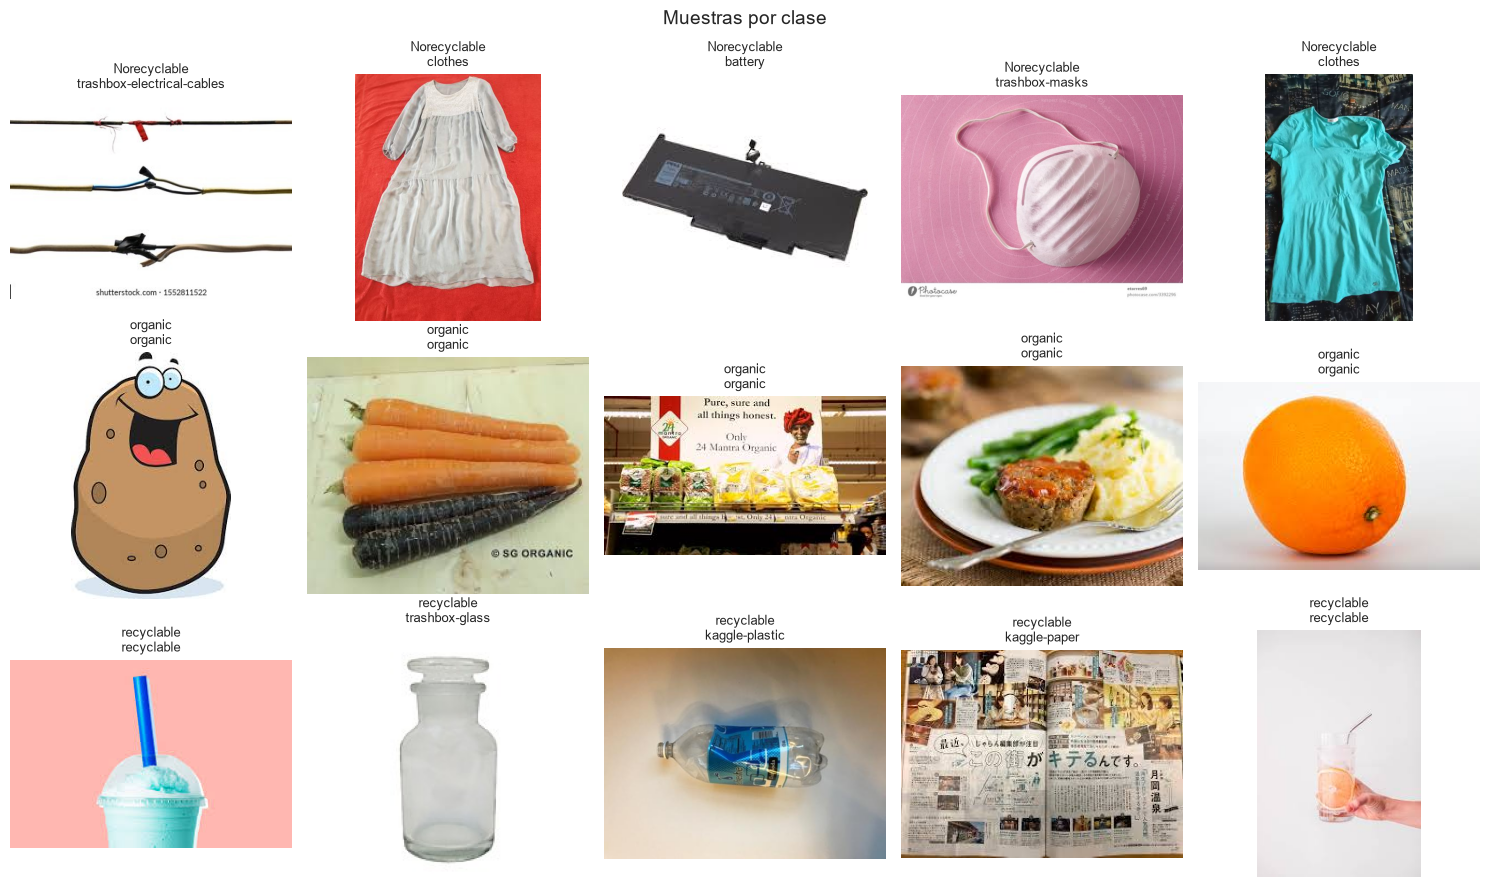

In [4]:
def show_samples_by_class(n_per_class=5):
    classes = list(all_files)
    fig, axes = plt.subplots(len(classes), n_per_class, figsize=(3 * n_per_class, 3 * len(classes)))
    for r, cls in enumerate(classes):
        for c, path in enumerate(random.sample(all_files[cls], n_per_class)):
            ax = axes[r][c]
            ax.imshow(Image.open(path).convert('RGB'))
            ax.set_title(f'{cls}\n{source_of(path)}', fontsize=9)
            ax.axis('off')
    fig.suptitle('Muestras por clase', fontsize=14)
    plt.tight_layout()
    plt.show()

show_samples_by_class()

## Datasets, balanceo, split y aumento de datos
- La ropa (`clothes`) y los zapatos (`shoes`) son muchas imágenes; se limita su cantidad para que "no reciclable" no se convierta en "ropa".
- Split estratificado 70% train / 15% val / 15% test por **clase + fuente**.
- Redimensiona a 224×224 (RGB) y normaliza con los valores de ImageNet.
- Augmentation únicamente en entrenamiento.

In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
NUM_WORKERS = 4  # procesos que cargan imágenes en paralelo (bajar a 0 si da problemas)

# Máximo de imágenes que se usan de algunas fuentes muy grandes
SOURCE_CAPS = {'clothes': 700, 'shoes': 500}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomAffine(degrees=20, translate=(0.1, 0.1), shear=10, scale=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Dos vistas del mismo directorio: una con augmentation y otra sin ella
train_full = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
eval_full = datasets.ImageFolder(DATA_ROOT, transform=eval_tf)

targets = np.array(train_full.targets)
sources = np.array([source_of(p) for p, _ in train_full.samples])

# Aplica los límites por fuente (muestra aleatoria reproducible)
rng = np.random.default_rng(SEED)
keep = np.ones(len(targets), dtype=bool)
for src, cap in SOURCE_CAPS.items():
    idx = np.where(sources == src)[0]
    if len(idx) > cap:
        keep[rng.choice(idx, len(idx) - cap, replace=False)] = False
indices = np.where(keep)[0]

# Estratifica por clase + fuente para que cada fuente aparezca en train, val y test
strata = np.array([f'{t}|{s}' for t, s in zip(targets[indices], sources[indices])])
train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=strata, random_state=SEED)
strata_temp = np.array([f'{targets[i]}|{sources[i]}' for i in temp_idx])
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=strata_temp, random_state=SEED)

train_ds = Subset(train_full, train_idx)
val_ds = Subset(eval_full, val_idx)
test_ds = Subset(eval_full, test_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=(device.type == 'cuda'), persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

CLASS_INDICES = train_full.class_to_idx
CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f'Imágenes usadas: {len(indices)} de {len(targets)}')
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')
print('Clases detectadas:', CLASS_INDICES)
print('Imágenes de entrenamiento por clase:', {CLASS_NAMES[k]: v for k, v in sorted(Counter(targets[train_idx]).items())})

Imágenes usadas: 39978 de 46080
Train: 27984 | Val: 5997 | Test: 5997
Clases detectadas: {'Norecyclable': 0, 'organic': 1, 'recyclable': 2}
Imágenes de entrenamiento por clase: {'Norecyclable': 5716, 'organic': 10729, 'recyclable': 11539}


## Baseline CNN (desde cero)

In [6]:
class CNNBaseline(nn.Module):
    def __init__(self, num_classes):
        super(CNNBaseline, self).__init__()

        # Bloques convolucionales
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        # Global Average Pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected
        self.fc1 = nn.Linear(256, 256)
        self.bn_fc = nn.BatchNorm1d(256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))

        x = self.gap(x)              # (B, 256, 1, 1)
        x = torch.flatten(x, 1)      # (B, 256)

        x = self.dropout(x)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.dropout(x)

        x = self.fc2(x)  # Sin softmax (se incluye en CrossEntropyLoss)
        return x

cnnbase = CNNBaseline(num_classes=NUM_CLASSES).to(device)
print(cnnbase)

CNNBaseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1): Linear(in_features=256, out_features=256, bias=True)
  (bn_fc): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, trac

## Transfer Learning (EfficientNet-B0)
- Usa pesos preentrenados de ImageNet.
- Primera fase: congela la base y entrena el clasificador.
- Segunda fase: descongela solamente los últimos bloques para fine-tuning con learning rate pequeño.

In [7]:
class EfficientNetModel(nn.Module):
    def __init__(self, num_classes):
        super(EfficientNetModel, self).__init__()

        # EfficientNet-B0 preentrenada con ImageNet
        self.base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # Primera fase: congelamos la base y entrenamos únicamente el clasificador.
        for param in self.base.features.parameters():
            param.requires_grad = False

        in_features = self.base.classifier[1].in_features
        self.base.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.base(x)

efficientnet = EfficientNetModel(num_classes=NUM_CLASSES).to(device)
print(efficientnet.base.classifier)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)


## Entrenamiento
- **Pesos por clase** en `CrossEntropyLoss` (la clase con menos imágenes pesa más).
- EarlyStopping, guardado del mejor modelo y ReduceLROnPlateau.
- Mixed precision (AMP) en GPU.

In [8]:
EPOCHS_HEAD = 5
EPOCHS_FINE = 12
PATIENCE = 4

model = efficientnet.to(device)

# Pesos inversamente proporcionales a la cantidad de imágenes de cada clase en train
train_counts = np.bincount(targets[train_idx], minlength=NUM_CLASSES)
class_weights = torch.tensor(train_counts.sum() / (NUM_CLASSES * train_counts), dtype=torch.float32, device=device)
print('Pesos por clase:', {c: round(w, 3) for c, w in zip(CLASS_NAMES, class_weights.tolist())})

criterion = nn.CrossEntropyLoss(weight=class_weights)
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def evaluate_loader(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

MODEL_DIR = '../backend/modelo'
os.makedirs(MODEL_DIR, exist_ok=True)
best_val_loss = float('inf')
best_state = None

def train_phase(model, epochs, optimizer, phase_name):
    global best_val_loss, best_state
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    patience_counter = 0

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss /= total
        train_acc = correct / total
        val_loss, val_acc = evaluate_loader(model, val_loader)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        current_lr = optimizer.param_groups[0]['lr']
        print(
            f'{phase_name} | Epoch {epoch+1}/{epochs} | '
            f'Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
            f'Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | '
            f'LR: {current_lr:.2e} | {time.time()-t0:.0f}s'
        )

        if patience_counter >= PATIENCE:
            print('Early stopping de esta fase activado.')
            break

# -------- FASE 1: solo la cabeza --------
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-4)
train_phase(model, EPOCHS_HEAD, optimizer, 'Cabeza')

# -------- FASE 2: fine-tuning de los últimos 3 bloques --------
for param in model.base.features.parameters():
    param.requires_grad = False
for block in model.base.features[-3:]:
    for param in block.parameters():
        param.requires_grad = True

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)
train_phase(model, EPOCHS_FINE, optimizer, 'Fine-tuning')

# Restaurar los mejores pesos encontrados durante todo el entrenamiento
if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)
    print('Mejores pesos restaurados.')

Pesos por clase: {'Norecyclable': 1.632, 'organic': 0.869, 'recyclable': 0.808}


Cabeza | Epoch 1/5 | Train Loss: 0.5662 | Val Loss: 0.4351 | Train Acc: 0.7776 | Val Acc: 0.8438 | LR: 1.00e-03 | 136s


Cabeza | Epoch 2/5 | Train Loss: 0.4869 | Val Loss: 0.4153 | Train Acc: 0.8106 | Val Acc: 0.8501 | LR: 1.00e-03 | 67s


Cabeza | Epoch 3/5 | Train Loss: 0.4726 | Val Loss: 0.4042 | Train Acc: 0.8155 | Val Acc: 0.8479 | LR: 1.00e-03 | 77s


Cabeza | Epoch 4/5 | Train Loss: 0.4754 | Val Loss: 0.3981 | Train Acc: 0.8131 | Val Acc: 0.8449 | LR: 1.00e-03 | 68s


Cabeza | Epoch 5/5 | Train Loss: 0.4734 | Val Loss: 0.3937 | Train Acc: 0.8140 | Val Acc: 0.8609 | LR: 1.00e-03 | 68s


... (5 outputs left out)

Fine-tuning | Epoch 6/12 | Train Loss: 0.1331 | Val Loss: 0.1695 | Train Acc: 0.9508 | Val Acc: 0.9411 | LR: 1.00e-04 | 62s


Fine-tuning | Epoch 7/12 | Train Loss: 0.1147 | Val Loss: 0.1690 | Train Acc: 0.9573 | Val Acc: 0.9441 | LR: 1.00e-04 | 58s


Fine-tuning | Epoch 8/12 | Train Loss: 0.0939 | Val Loss: 0.1671 | Train Acc: 0.9646 | Val Acc: 0.9460 | LR: 5.00e-05 | 58s


Fine-tuning | Epoch 9/12 | Train Loss: 0.0824 | Val Loss: 0.1680 | Train Acc: 0.9689 | Val Acc: 0.9450 | LR: 5.00e-05 | 60s
Early stopping de esta fase activado.
Mejores pesos restaurados.


## Curvas de entrenamiento

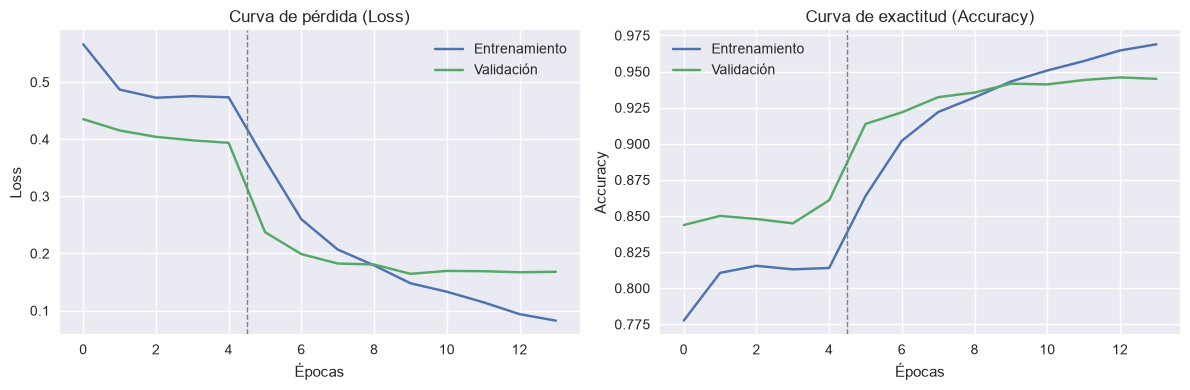

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Entrenamiento')
axes[0].plot(history['val_loss'], label='Validación')
axes[0].axvline(EPOCHS_HEAD - 0.5, color='gray', ls='--', lw=1)
axes[0].set_title('Curva de pérdida (Loss)')
axes[0].set_xlabel('Épocas'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history['train_acc'], label='Entrenamiento')
axes[1].plot(history['val_acc'], label='Validación')
axes[1].axvline(EPOCHS_HEAD - 0.5, color='gray', ls='--', lw=1)
axes[1].set_title('Curva de exactitud (Accuracy)')
axes[1].set_xlabel('Épocas'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluación (Test)
- Accuracy, **Balanced Accuracy**, **Macro-F1**.
- Matriz de confusión y reporte por clase.

Accuracy: 0.9451 | Balanced Accuracy: 0.9457 | Macro-F1: 0.9420

Reporte de clasificación:
               precision    recall  f1-score   support

No reciclable     0.8999    0.9469    0.9228      1225
     Orgánico     0.9721    0.9552    0.9636      2299
   Reciclable     0.9441    0.9349    0.9395      2473

     accuracy                         0.9451      5997
    macro avg     0.9387    0.9457    0.9420      5997
 weighted avg     0.9458    0.9451    0.9453      5997



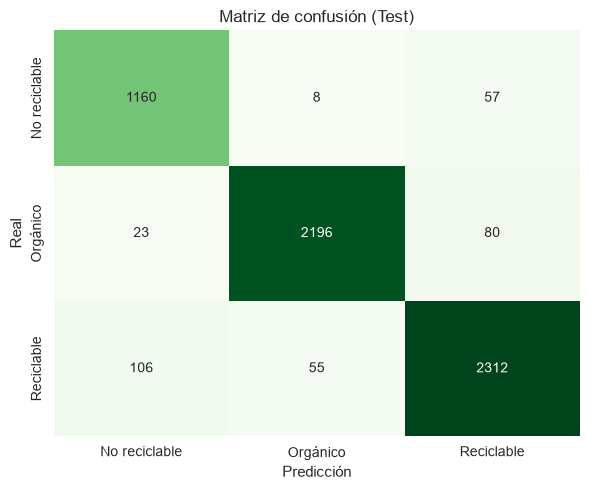

In [10]:
def predict_loader(model, loader):
    model.eval()
    probs, targets_ = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
            probs.append(F.softmax(outputs.float(), dim=1).cpu().numpy())
            targets_.append(labels.numpy())
    return np.concatenate(probs), np.concatenate(targets_)

LABELS_ES = {'organic': 'Orgánico', 'recyclable': 'Reciclable', 'Norecyclable': 'No reciclable'}
TARGET_NAMES = [LABELS_ES[c] for c in CLASS_NAMES]

test_probs, y_true = predict_loader(model, test_loader)
y_pred = test_probs.argmax(1)

acc = (y_pred == y_true).mean()
bal_acc = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average='macro')

print(f'Accuracy: {acc:.4f} | Balanced Accuracy: {bal_acc:.4f} | Macro-F1: {macro_f1:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_true, y_pred, target_names=TARGET_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES)
plt.title('Matriz de confusión (Test)')
plt.xlabel('Predicción'); plt.ylabel('Real')
plt.tight_layout()
plt.show()

### Aciertos por tipo de objeto (test)
Porcentaje de imágenes de cada fuente/objeto que el modelo clasificó en la clase correcta.
Permite ver, por ejemplo, qué tan bien reconoce **pilas** o **celulares**.

In [11]:
test_sources = sources[test_idx]
per_source = (pd.DataFrame({'clase': [LABELS_ES[CLASS_NAMES[t]] for t in y_true],
                            'objeto': test_sources,
                            'acierto': (y_pred == y_true)})
              .groupby(['clase', 'objeto'])['acierto'].agg(['mean', 'count'])
              .rename(columns={'mean': 'acierto (%)', 'count': 'imágenes test'})
              .sort_values(['clase', 'acierto (%)']))
per_source['acierto (%)'] = (per_source['acierto (%)'] * 100).round(1)
display(per_source)

acierto (%)  imágenes test
clase         objeto                                                 
No reciclable trashnet-trash                      81.0             21
              trashbox-medicines                  81.7             60
              realwaste-misc-trash                90.7             75
              trash                               92.3            104
              realwaste-textile                   93.6             47
              trashbox-electrical-cables          94.0             83
              trashbox-gloves                     94.3             53
              battery                             94.4            142
              trashbox-masks                      95.0             60
              trashbox-syringe                    95.1             61
              shoes                               96.0             75
              trashbox-laptops                    96.7             60
              trashbox-small-appliances           97.3            111
              trashbox-electronic-chips           98.6             74
              clothes                             99.0            105
              trashbox-cigarette-butt            100.0             61
              trashbox-smartphones               100.0             33
Orgánico      organic                             95.2           2082
              realwaste-food                      96.8             62
              kaggle-biological                   98.9             90
              realwaste-vegetation               100.0             65
Reciclable    trashbox-cardboard                  68.9             45
              trashbox-glass                      82.2             45
              trashbox-plastic-bottles            84.4             45
              trashbox-tetra-pak                  86.7             45
              trashnet-paper                      86.7             30
              kaggle-paper                        90.0             30
              realwaste-cardboard                 90.0             30
              realwaste-plastic                   90.0             30
              trashnet-metal                      90.0             30
              kaggle-brown-glass                  93.3             30
              kaggle-metal                        93.3             30
              realwaste-metal                     93.3             30
              trashbox-beverage-cans              93.3             45
              trashbox-plastic-containers         93.3             45
              recyclable                          94.3           1624
              trashbox-news-paper                 95.8             24
              realwaste-glass                     96.7             30
              realwaste-paper                     96.7             30
              trashnet-cardboard                  96.7             30
              trashnet-plastic                    96.7             30
              trashbox-metal-containers           97.8             45
              kaggle-cardboard                   100.0             30
              kaggle-green-glass                 100.0             30
              kaggle-plastic                     100.0             30
              kaggle-white-glass                 100.0             30
              trashnet-glass                     100.0             30

## Umbral de confianza (respaldo)
Aunque ahora existe la clase **No reciclable**, puede llegar un objeto que el modelo nunca vio.
Si la probabilidad máxima es menor que el `UMBRAL`, el modelo "duda" y el residuo se trata como **No reciclable**
(lo más seguro: es mejor no contaminar la caneca blanca o verde).

El umbral se calibra en **validación** para conservar el 97% de las predicciones.

Umbral elegido: 0.6081
Imágenes de test bajo el umbral (enviadas a No reciclable): 2.80%
Accuracy sin umbral: 0.9451 | con umbral: 0.9358


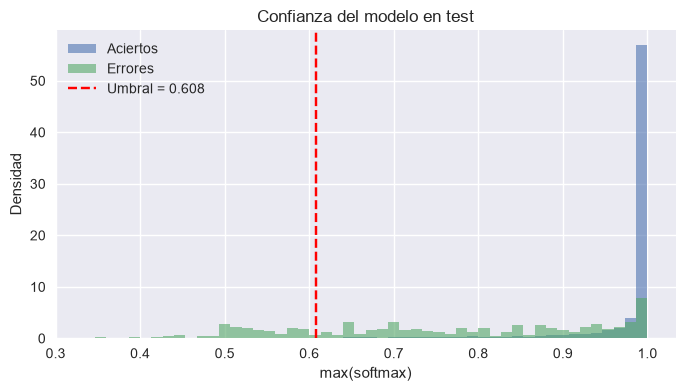

In [12]:
val_probs, y_val = predict_loader(model, val_loader)
TARGET_KEEP = 0.97
THRESHOLD = float(np.quantile(val_probs.max(1), 1 - TARGET_KEEP))

NR_IDX = CLASS_INDICES['Norecyclable']
conf_test = test_probs.max(1)
y_pred_thr = np.where(conf_test >= THRESHOLD, y_pred, NR_IDX)

print(f'Umbral elegido: {THRESHOLD:.4f}')
print(f'Imágenes de test bajo el umbral (enviadas a No reciclable): {(conf_test < THRESHOLD).mean():.2%}')
print(f'Accuracy sin umbral: {acc:.4f} | con umbral: {(y_pred_thr == y_true).mean():.4f}')

bins = np.linspace(1 / NUM_CLASSES, 1.0, 51)
plt.figure(figsize=(8, 4))
plt.hist(conf_test[y_pred == y_true], bins=bins, alpha=0.6, density=True, label='Aciertos')
plt.hist(conf_test[y_pred != y_true], bins=bins, alpha=0.6, density=True, label='Errores')
plt.axvline(THRESHOLD, color='red', ls='--', label=f'Umbral = {THRESHOLD:.3f}')
plt.title('Confianza del modelo en test')
plt.xlabel('max(softmax)'); plt.ylabel('Densidad')
plt.legend()
plt.show()

## Predicción final

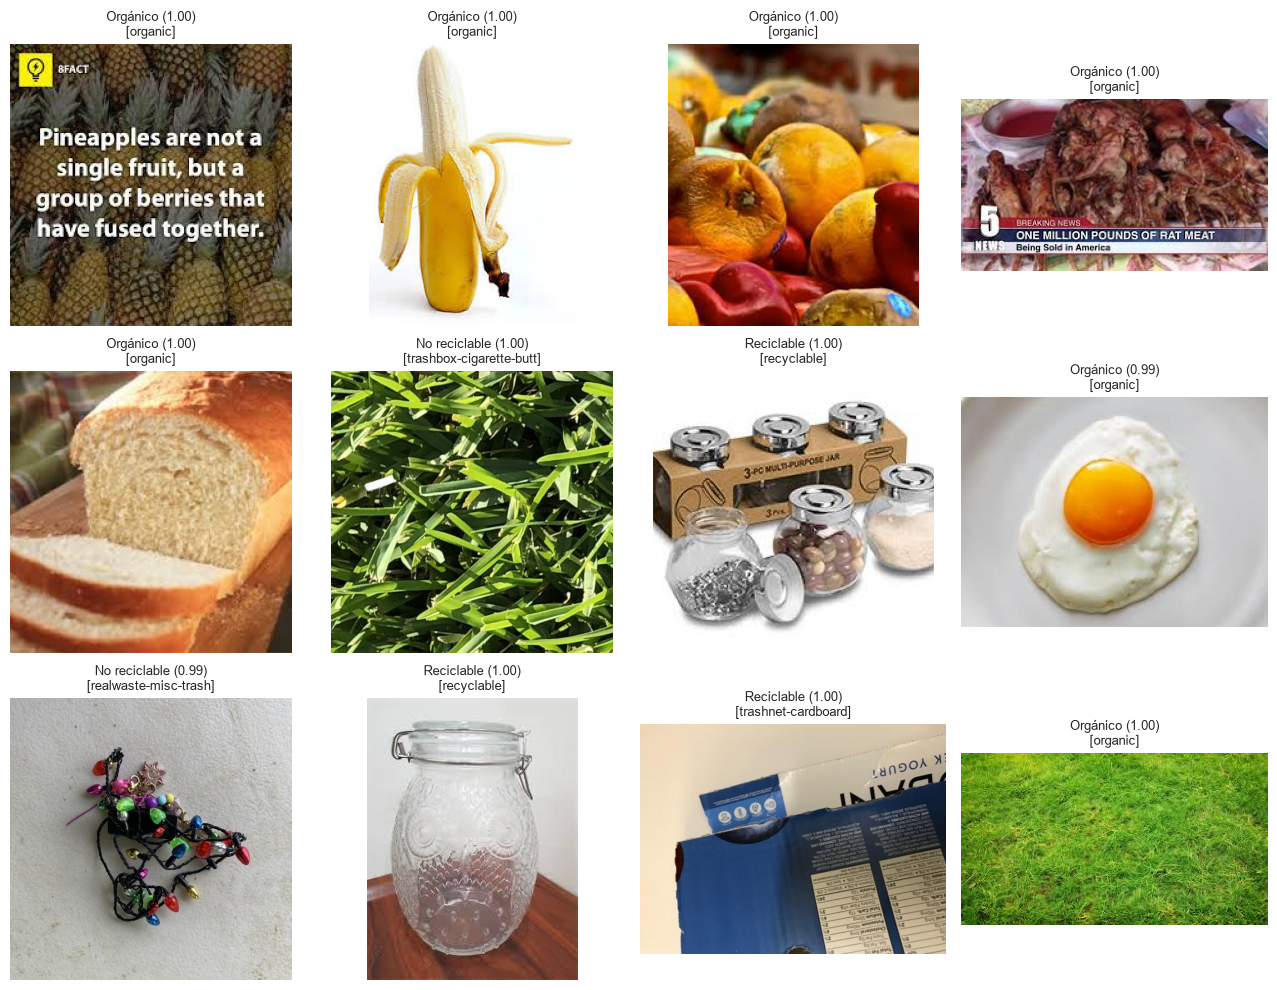

In [13]:
def predict_image(path, model=model, threshold=THRESHOLD):
    img = Image.open(path).convert('RGB')
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x).float(), dim=1)[0].cpu().numpy()
    conf = float(probs.max())
    cls = CLASS_NAMES[probs.argmax()] if conf >= threshold else 'Norecyclable'
    return LABELS_ES[cls], conf

# Ejemplos aleatorios de test
samples = [eval_full.samples[i][0] for i in np.random.choice(test_idx, 12, replace=False)]

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, path in zip(axes.ravel(), samples):
    label, conf = predict_image(path)
    ax.imshow(Image.open(path).convert('RGB'))
    ax.set_title(f'{label} ({conf:.2f})\n[{source_of(path)}]', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Guardado del modelo
Se guardan los pesos y un archivo JSON con las clases, el umbral y las métricas (lo usa la página web).

In [14]:
model_path = os.path.join(MODEL_DIR, 'modelo_residuos_final.pth')
torch.save({k: v.cpu() for k, v in model.state_dict().items()}, model_path)

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
config = {
    'architecture': 'efficientnet_b0',
    'classes': CLASS_NAMES,
    'labels_es': {c: LABELS_ES[c] for c in CLASS_NAMES},
    'categories': {'organic': 'organic', 'recyclable': 'recyclable', 'Norecyclable': 'non_recyclable'},
    'fallback_class': 'Norecyclable',
    'threshold': THRESHOLD,
    'img_size': list(IMG_SIZE),
    'mean': IMAGENET_MEAN,
    'std': IMAGENET_STD,
    'dataset': {'total': int(len(indices)), 'train': len(train_idx), 'val': len(val_idx), 'test': len(test_idx)},
    'test_metrics': {
        'accuracy': float(acc), 'balanced_accuracy': float(bal_acc), 'macro_f1': float(macro_f1),
        'recall_por_clase': {c: float(report[c]['recall']) for c in CLASS_NAMES},
    },
}
with open(os.path.join(MODEL_DIR, 'modelo_residuos_config.json'), 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print(f'Modelo de PyTorch guardado exitosamente en: {model_path}')
print('Configuración guardada en:', os.path.join(MODEL_DIR, 'modelo_residuos_config.json'))

Modelo de PyTorch guardado exitosamente en: ../backend/modelo\modelo_residuos_final.pth
Configuración guardada en: ../backend/modelo\modelo_residuos_config.json
